In [1]:
%pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


In [3]:
# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Define class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

# Display dataset shape
print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

C:\Users\HP\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


Training Data: (50000, 32, 32, 3)
Testing Data: (10000, 32, 32, 3)


In [4]:
# Resize images to 96x96 for MobileNetV2
x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))

# Convert images to float32
x_train = tf.cast(x_train, tf.float32)
x_test = tf.cast(x_test, tf.float32)

# Convert labels into one-dimensional arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

# Display shapes
print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (50000, 96, 96, 3)
Testing Shape: (10000, 96, 96, 3)


In [5]:
# Load MobileNetV2 pretrained on ImageNet
base_model = keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Display pretrained model
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_1.00_96"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 96, 96, 3)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 48, 48, 32)        │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 48, 48, 32)        │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 48, 48, 32)        │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 48, 48, 32)        │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 48, 48, 32)        │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 48, 48, 32)        │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 48, 48, 16)        │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 48, 48, 16)        │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 48, 48, 96)        │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 48, 48, 96)        │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 48, 48, 96)        │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 49, 49, 96)        │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 24, 24, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
# Define input layer
inputs = keras.Input(shape=(96, 96, 3))

# Preprocess input for MobileNetV2
x = keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract features using pretrained model
x = base_model(x, training=False)

# Apply global average pooling
x = layers.GlobalAveragePooling2D()(x)

# Add dropout layer
x = layers.Dropout(0.3)(x)

# Add output layer for 10 classes
outputs = layers.Dense(10, activation='softmax')(x)

# Create complete model
model = keras.Model(inputs, outputs)

# Display model architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_96 (Functional)     │ (None, 3, 3, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          12,810 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# Compile model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
# Train custom classifier with frozen CNN base
history = model.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=64,
    validation_split=0.2
)

print("Initial training completed!")

Epoch 1/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 275s 428ms/step - accuracy: 0.8047 - loss: 0.5792 - val_accuracy: 0.8472 - val_loss: 0.4431
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 246s 394ms/step - accuracy: 0.8638 - loss: 0.3997 - val_accuracy: 0.8554 - val_loss: 0.4169
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 273s 436ms/step - accuracy: 0.8777 - loss: 0.3600 - val_accuracy: 0.8588 - val_loss: 0.4088
Initial training completed!


In [9]:
# Unfreeze pretrained model
base_model.trainable = True

# Freeze all but the last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Recompile with a small learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune the model
history_fine = model.fit(
    x_train,
    y_train,
    epochs=2,
    batch_size=64,
    validation_split=0.2
)

print("Fine-tuning completed!")

Epoch 1/2
625/625 ━━━━━━━━━━━━━━━━━━━━ 333s 518ms/step - accuracy: 0.8965 - loss: 0.3052 - val_accuracy: 0.8706 - val_loss: 0.3776
Epoch 2/2
625/625 ━━━━━━━━━━━━━━━━━━━━ 288s 460ms/step - accuracy: 0.9132 - loss: 0.2572 - val_accuracy: 0.8750 - val_loss: 0.3660
Fine-tuning completed!


In [10]:
# Evaluate using testing data
test_loss, test_accuracy = model.evaluate(x_test, y_test)

# Display results
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 167ms/step - accuracy: 0.8710 - loss: 0.3765
Test Loss: 0.3764841556549072
Test Accuracy: 87.09999918937683 %


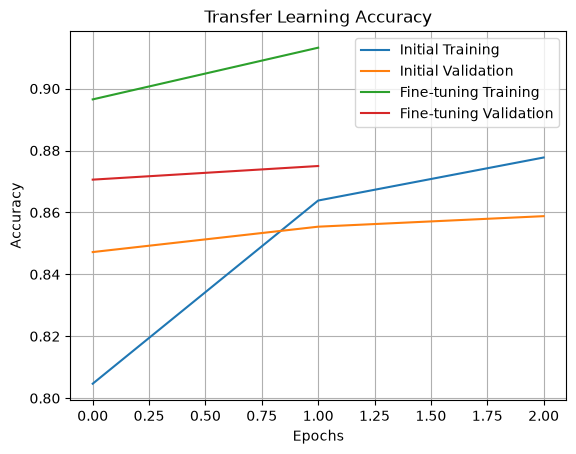

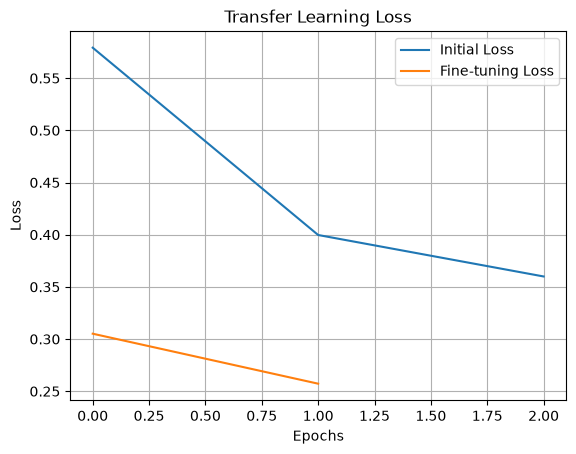

In [11]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Initial Training')
plt.plot(history.history['val_accuracy'], label='Initial Validation')

plt.plot(history_fine.history['accuracy'], label='Fine-tuning Training')
plt.plot(history_fine.history['val_accuracy'], label='Fine-tuning Validation')

plt.title("Transfer Learning Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Plot training loss
plt.plot(history.history['loss'], label='Initial Loss')
plt.plot(history_fine.history['loss'], label='Fine-tuning Loss')

plt.title("Transfer Learning Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [12]:
# Predict first 10 testing images
predictions = model.predict(x_test[:10])

# Get predicted class indexes
predicted_labels = np.argmax(predictions, axis=1)

# Display actual and predicted labels
for i in range(10):
    print(
        "Actual:", class_names[y_test[i]],
        "| Predicted:", class_names[predicted_labels[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Actual: Cat | Predicted: Cat
Actual: Ship | Predicted: Ship
Actual: Ship | Predicted: Ship
Actual: Airplane | Predicted: Airplane
Actual: Frog | Predicted: Frog
Actual: Frog | Predicted: Frog
Actual: Automobile | Predicted: Automobile
Actual: Frog | Predicted: Frog
Actual: Cat | Predicted: Cat
Actual: Automobile | Predicted: Automobile


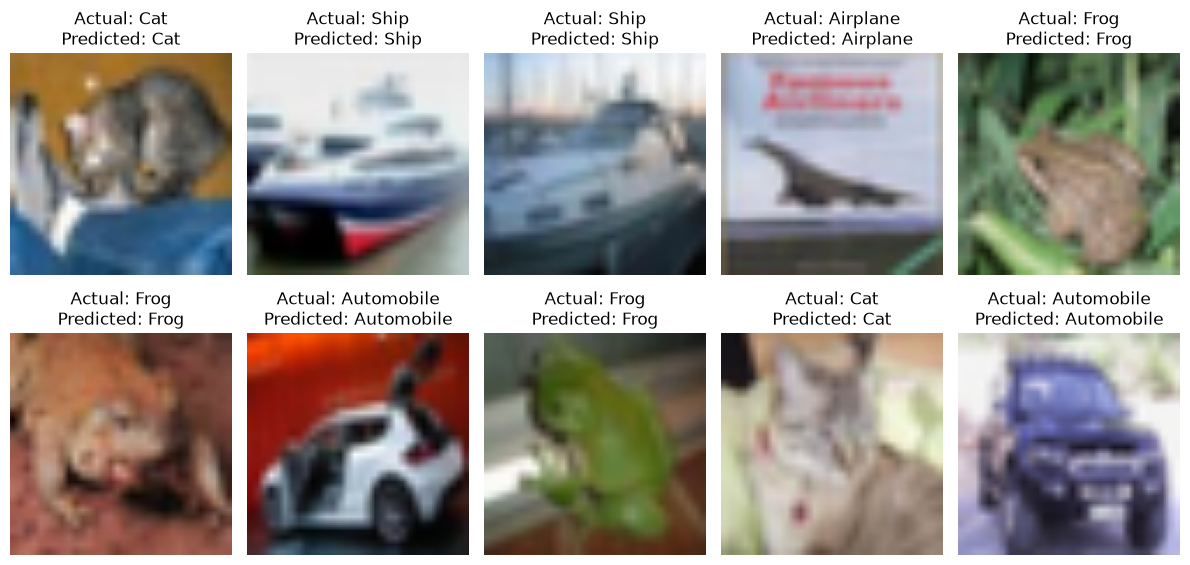

In [13]:
# Display predicted images
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_test[i].numpy().astype('uint8'))

    # Display actual and predicted labels
    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted_labels[i]]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()